# CISC7204 Assignment 02 — Module 01 · Lab 02
## Introduction to Matplotlib and Line Plots

| | |
|---|---|
| **Student ID** | MC664961 |
| **Student Name** | SHENG TIAN |
| **Course** | CISC7204 — Data Science Programming (Assignment 02) |
| **Module / Lab** | Module 01 — Introduction to Data Visualization / Lab 02 |
| **Notebook** | `CISC7204 Assgn02 Module 01 - Lab02 MC664961 SHENG TIAN.ipynb` |
| **Environment** | Jupyter Notebook, Python 3 (Anaconda Distribution), Matplotlib + pandas |

### What this lab is about

Module 01 introduces the two workhorses of Python data visualisation: **pandas** for
wrangling the data and **Matplotlib** for drawing it. This lab walks through the whole
path that a real analysis takes — read the dataset, clean it, reshape it, look things
up by label, and only then draw a **line plot** — because a chart is only as good as
the dataframe behind it.

The dataset is *Immigration to Canada from 1980 to 2013* (United Nations, 2015 revision).
Each row is a source country and each column a year, so the data is already in the shape
a line plot wants: time along the x-axis, one line per country.

### Learning objectives (each one is demonstrated below)

1. Read an Excel sheet into a DataFrame with `pandas.read_excel()` and inspect it
   (`head`, `tail`, `info`, `columns`, `index`, `shape`).
2. Clean the frame: drop irrelevant columns, rename columns, add a computed `Total`
   column, check for missing values.
3. Select and slice data by column label, by row label (`loc`) and by position (`iloc`).
4. Filter rows with a boolean condition.
5. Draw a line plot the *pandas* way (`df.plot()`), then control it the *Matplotlib* way
   (title, axis labels, `plt.text()` annotation, `plt.show()`).
6. Transpose a DataFrame so that pandas puts the years on the x-axis.
7. Compare the immigration trend of the top 5 source countries.

> **Data note.** The notebook looks for the dataset in a local `data/` folder first and
> falls back to the course URL, so the same file runs on a machine with or without an
> internet connection.

---
## Step 1 — Import the libraries

`pandas` holds the data, `numpy` does the numerical work. Printing the versions makes the
notebook self-documenting: a screenshot of a version banner is proof of *which* stack
produced the figures.

In [1]:
import sys

import numpy as np      # numerical work
import pandas as pd     # data structures

# keep the very wide frames (43 columns) readable inside a notebook cell
pd.set_option("display.max_columns", 8)
pd.set_option("display.width", 120)

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)

Python      : 3.14.6
pandas      : 3.0.3
numpy       : 2.4.6


## Step 2 — Read the dataset into a DataFrame

`read_excel()` needs three arguments that matter here:

* `sheet_name='Canada by Citizenship'` — the workbook holds several sheets, only this one
  contains the immigration numbers.
* `skiprows=range(20)` — the first 20 rows are the United Nations report title, the
  country code table and blank spacer rows.
* `skipfooter=2` — the last two rows are footnotes ("Notes: ..."), not data.

Dropping those rows is exactly the *pre-processing* part of the lab: without it the first
"country" of the frame would be a footnote.

In [2]:
DATA_DIR = "data/"
URL = ("https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
       "IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/")

def data_file(name):
    """Use the local copy when it is shipped with the notebook, else the course URL."""
    from pathlib import Path
    local = Path(DATA_DIR) / name
    return str(local) if local.exists() else URL + name.replace(" ", "%20")

df_can = pd.read_excel(
    data_file("Canada.xlsx"),
    sheet_name="Canada by Citizenship",
    skiprows=range(20),
    skipfooter=2)

print("Data read into a pandas dataframe!")
print("Source:", data_file("Canada.xlsx"))
print("Dimensions (rows, columns):", df_can.shape)

Data read into a pandas dataframe!
Source: data/Canada.xlsx
Dimensions (rows, columns): (195, 43)


### 2.1 First look — `head()`

In [3]:
df_can.head()

,Type,Coverage,OdName,AREA,...,2010,2011,2012,2013
0,Immigrants,Foreigners,Afghanistan,935,...,1758,2203,2635,2004
1,Immigrants,Foreigners,Albania,908,...,561,539,620,603
2,Immigrants,Foreigners,Algeria,903,...,4752,4325,3774,4331
3,Immigrants,Foreigners,American Samoa,909,...,0,0,0,0
4,Immigrants,Foreigners,Andorra,908,...,0,0,1,1


### 2.2 Last look — `tail()`

The 195 rows are 195 source countries/territories; the columns are `Type`, `Coverage`,
`OdName` (the country name), `AREA`, `REG`, `DEV` (development index), `AreaName`,
`RegName` and one column per year from 1980 to 2013.

In [4]:
df_can.tail()

,Type,Coverage,OdName,AREA,...,2010,2011,2012,2013
190,Immigrants,Foreigners,Viet Nam,935,...,1942,1723,1731,2112
191,Immigrants,Foreigners,Western Sahara,903,...,0,0,0,0
192,Immigrants,Foreigners,Yemen,935,...,211,160,174,217
193,Immigrants,Foreigners,Zambia,903,...,102,69,46,59
194,Immigrants,Foreigners,Zimbabwe,903,...,494,434,437,407


### 2.3 Structure — `info()`, `columns`, `index`, `shape`

`info()` is the quick health check: 195 entries, no missing values, the year columns are
`int64` and only the descriptive columns are text. `columns` and `index` are *not* plain
lists (they are pandas `Index` objects) — `tolist()` converts them when a real list is
needed, which we do further down.

In [5]:
df_can.info(verbose=False)

print("\ntype(df_can.columns):", type(df_can.columns))
print("type(df_can.index)  :", type(df_can.index))
print("\nColumn labels:")
print(df_can.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Columns: 43 entries, Type to 2013
dtypes: int64(37), str(6)
memory usage: 79.3 KB

type(df_can.columns): <class 'pandas.Index'>
type(df_can.index)  : <class 'pandas.RangeIndex'>

Column labels:
['Type', 'Coverage', 'OdName', 'AREA', 'AreaName', 'REG', 'RegName', 'DEV', 'DevName', 1980, 1981, 1982, 1983, 1984, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1992, 1993, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2008, 2009, 2010, 2011, 2012, 2013]


In [6]:
print("Index labels (first 10):", df_can.index.tolist()[:10])
print("type after tolist()    :", type(df_can.columns.tolist()))
print("\nDataFrame dimensions   :", df_can.shape)

Index labels (first 10): [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
type after tolist()    : <class 'list'>

DataFrame dimensions   : (195, 43)


## Step 3 — Clean the frame

Four operations, each one a standard tidy-up:

| Operation | Code | Why |
|---|---|---|
| Drop columns | `df_can.drop([...], axis=1)` | `AREA`, `REG`, `DEV`, `Type`, `Coverage` are codes/redundant labels |
| Rename columns | `df_can.rename(columns={...})` | `OdName` → `Country`, `AreaName` → `Continent`, `RegName` → `Region` |
| Add a metric | `df_can['Total']` | cumulative immigration 1980–2013, used later to rank countries |
| Check quality | `isnull().sum()`, `describe()` | confirm no gaps before plotting |

> **Note on `Total`.** The lab writes `df_can.sum(axis=1)`. With pandas ≥ 2 that call also
> tries to add the *text* columns and raises `TypeError`, so we sum explicitly over the
> year columns — same number, no ambiguity.

In [7]:
# axis=0 is rows (the default), axis=1 is columns
df_can.drop(["AREA", "REG", "DEV", "Type", "Coverage"], axis=1, inplace=True)

df_can.rename(columns={"OdName": "Country",
                       "AreaName": "Continent",
                       "RegName": "Region"}, inplace=True)

# make every column label a string so year 2013 can never be confused with position 2013
df_can.columns = list(map(str, df_can.columns))

years = list(map(str, range(1980, 2014)))   # 1980 ... 2013, reused for every plot
df_can["Total"] = df_can[years].sum(axis=1)

print("Columns after cleaning:")
print(df_can.columns.tolist())

Columns after cleaning:
['Country', 'Continent', 'Region', 'DevName', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', 'Total']


In [8]:
print("Missing values per column (top 5):")
print(df_can.isnull().sum().head(5))
print("\nAny missing value in the whole frame?", df_can.isnull().values.any())

df_can.describe().round(1)

Missing values per column (top 5):
Country      0
Continent    0
Region       0
DevName      0
1980         0
dtype: int64

Any missing value in the whole frame? False


,1980,1981,1982,1983,...,2011,2012,2013,Total
count,195.0,195.0,195.0,195.0,...,195.0,195.0,195.0,195.0
mean,508.4,567.0,534.7,387.4,...,1262.5,1314.0,1320.7,32867.5
std,1949.6,2152.6,1867.0,1204.3,...,4030.1,4247.6,4238.0,91785.5
min,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0
25%,0.0,0.0,0.0,0.0,...,37.5,42.5,45.0,952.0
50%,13.0,10.0,11.0,12.0,...,179.0,233.0,213.0,5018.0
75%,251.5,295.5,275.0,173.0,...,772.0,783.0,796.0,22239.5
max,22045.0,24796.0,20620.0,10015.0,...,36765.0,34315.0,34129.0,691904.0


## Step 4 — Indexing and selection

Two ways to get a column:

* `df_can.Country` — quick, but only works when the name has no spaces or special characters.
* `df_can[['Country', 1980, 1981]]` — always works, and returns a DataFrame instead of a Series.

In [9]:
df_can.Country        # a Series (one column)

0         Afghanistan
1             Albania
2             Algeria
3      American Samoa
4             Andorra
            ...      
190          Viet Nam
191    Western Sahara
192             Yemen
193            Zambia
194          Zimbabwe
Name: Country, Length: 195, dtype: str

In [10]:
df_can[["Country", "1980", "1981", "1982", "1983", "1984", "1985"]].head()

,Country,1980,1981,1982,1983,1984,1985
0,Afghanistan,16,39,39,47,71,340
1,Albania,1,0,0,0,0,0
2,Algeria,80,67,71,69,63,44
3,American Samoa,0,1,0,0,0,0
4,Andorra,0,0,0,0,0,0


### 4.1 Rows by label — `loc`

The default index is 0…194, which is useless for lookup ("which row is Japan?").
`set_index('Country')` turns the country name into the row label, so `df_can.loc['Japan']`
just works. `df_can.iloc[87]` is the *positional* equivalent.

In [11]:
df_can.set_index("Country", inplace=True)
df_can.index.name = None          # optional: drop the index name for a cleaner printout

print("New dimensions:", df_can.shape)
df_can.head(3)

New dimensions: (195, 38)


,Continent,Region,DevName,1980,...,2011,2012,2013,Total
Afghanistan,Asia,Southern Asia,Developing regions,16,...,2203,2635,2004,58639
Albania,Europe,Southern Europe,Developed regions,1,...,539,620,603,15699
Algeria,Africa,Northern Africa,Developing regions,80,...,4325,3774,4331,69439


In [12]:
# (1) the full row for Japan
df_can.loc["Japan"]

Continent                 Asia
Region            Eastern Asia
DevName      Developed regions
1980                       701
1981                       756
1982                       598
1983                       309
1984                       246
1985                       198
1986                       248
1987                       422
1988                       324
1989                       494
1990                       379
1991                       506
1992                       605
1993                       907
1994                       956
1995                       826
1996                       994
1997                       924
1998                       897
1999                      1083
2000                      1010
2001                      1092
2002                       806
2003                       817
2004                       973
2005                      1067
2006                      1212
2007                      1250
2008                      1284
2009    

In [13]:
# (2) one year for one country  ->  .loc[label, column]
print("Japan, 2013 (loc)  :", df_can.loc["Japan", "2013"])

# (3) years 1980-1985 for Japan  ->  .loc[label, list_of_columns]
df_can.loc["Japan", ["1980", "1981", "1982", "1983", "1984", "1985"]]

Japan, 2013 (loc)  : 982


1980    701
1981    756
1982    598
1983    309
1984    246
1985    198
Name: Japan, dtype: int64

### 4.2 Filtering with a boolean condition

`df_can['Continent'] == 'Asia'` builds a True/False Series; passing it back into
`df_can[...]` keeps the rows where the answer is True. Combine conditions with `&` / `|`
(not `and` / `or`) and wrap each one in parentheses.

In [14]:
condition = df_can["Continent"] == "Asia"
print("Rows that satisfy the condition:", condition.sum(), "of", len(df_can))

df_can[condition].head()

Rows that satisfy the condition: 49 of 195


,Continent,Region,DevName,1980,...,2011,2012,2013,Total
Afghanistan,Asia,Southern Asia,Developing regions,16,...,2203,2635,2004,58639
Armenia,Asia,Western Asia,Developing regions,0,...,236,258,207,3310
Azerbaijan,Asia,Western Asia,Developing regions,0,...,138,161,57,2649
Bahrain,Asia,Western Asia,Developing regions,0,...,21,39,32,475
Bangladesh,Asia,Southern Asia,Developing regions,83,...,2694,2640,3789,65568


In [15]:
# Asia AND Southern Asia
df_can[(df_can["Continent"] == "Asia") & (df_can["Region"] == "Southern Asia")]

,Continent,Region,DevName,1980,...,2011,2012,2013,Total
Afghanistan,Asia,Southern Asia,Developing regions,16,...,2203,2635,2004,58639
Bangladesh,Asia,Southern Asia,Developing regions,83,...,2694,2640,3789,65568
Bhutan,Asia,Southern Asia,Developing regions,0,...,1879,1075,487,5876
India,Asia,Southern Asia,Developing regions,8880,...,27509,30933,33087,691904
Iran (Islamic Republic of),Asia,Southern Asia,Developing regions,1172,...,7479,7534,11291,175923
Maldives,Asia,Southern Asia,Developing regions,0,...,3,1,1,30
Nepal,Asia,Southern Asia,Developing regions,1,...,1129,1185,1308,10222
Pakistan,Asia,Southern Asia,Developing regions,978,...,7468,11227,12603,241600
Sri Lanka,Asia,Southern Asia,Developing regions,185,...,3309,3338,2394,148358


---
## Step 5 — Bring in Matplotlib

`matplotlib.pyplot` is the scripting layer: a collection of command-style functions that
draw onto "the current figure", which is why `plt.title()` after `df.plot()` lands on the
plot we just made. `%matplotlib inline` is the Jupyter magic that puts the figure in the
output cell instead of a separate window; `mpl.style.use('ggplot')` applies a nicer
default theme.

In [16]:
%matplotlib inline

import matplotlib as mpl
import matplotlib.pyplot as plt

print("Matplotlib version:", mpl.__version__)
mpl.style.use("ggplot")              # optional: ggplot-like style
print("Style applied     : ggplot  (axes.grid =", plt.rcParams["axes.grid"], ")")

Matplotlib version: 3.11.0
Style applied     : ggplot  (axes.grid = True )


---
## Step 6 — A first line plot: immigration from Haiti

**Why a line plot?** A line plot shows a continuous quantity against a continuous axis —
here *number of immigrants per year*. The eye follows the slope, so a sudden jump is
immediately visible: exactly what we need for the Haiti case study.

In 2010 Haiti was hit by a magnitude 7.0 earthquake. Canada's humanitarian response shows
up in the data as a spike in arrivals.

In [17]:
haiti = df_can.loc["Haiti", years]      # a Series: index = years, values = immigrants
print(type(haiti))
haiti.head()

<class 'pandas.Series'>


1980    1666
1981    3692
1982    3498
1983    2860
1984    1418
Name: Haiti, dtype: int64

### 6.1 The pandas one-liner

`Series.plot()` is pandas' built-in Matplotlib wrapper: index on the x-axis, values on the
y-axis. The plot is drawn, but the year labels are missing.

<Axes: >

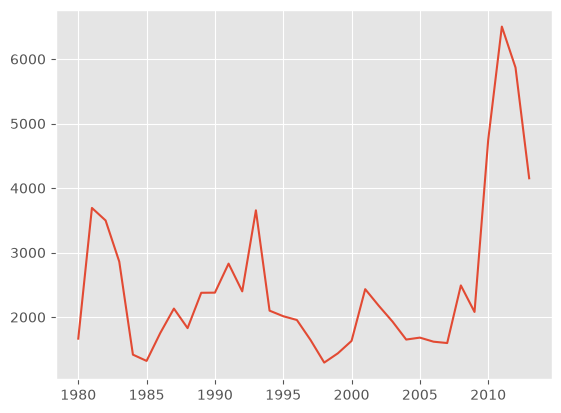

In [18]:
haiti.plot()      # years are still strings here, so pandas draws an unlabelled category axis

### 6.2 Make it a proper chart

Two fixes turn that sketch into a chart we could put in a report: cast the index to
`int` so Matplotlib can lay out a numeric axis, and label the title and both axes.

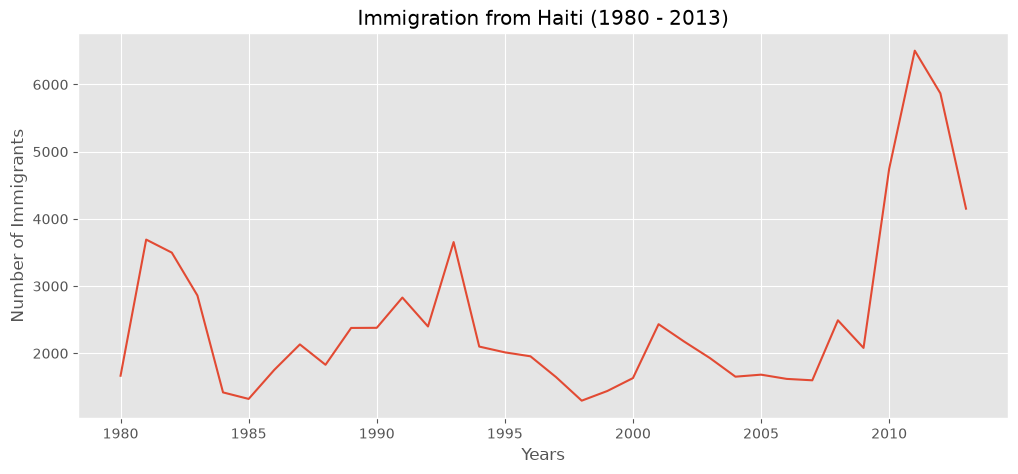

In [19]:
haiti.index = haiti.index.map(int)      # string years -> integer year numbers

haiti.plot(kind="line", figsize=(12, 5))

plt.title("Immigration from Haiti (1980 - 2013)")
plt.ylabel("Number of Immigrants")
plt.xlabel("Years")

plt.show()      # needed to flush the updates made after .plot()

### 6.3 Annotate the story

`plt.text(x, y, label)` writes on the current axes at data coordinates. Because the x-axis
is now numeric, `x=2000` means *the year 2000*, not *the 2000th pixel* — the classic trap
when the axis is still made of string categories.

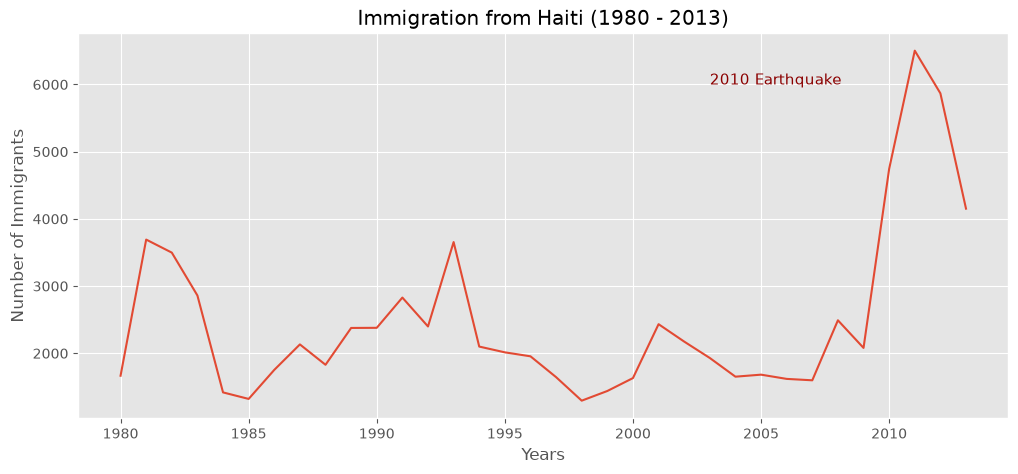

In [20]:
haiti.plot(kind="line", figsize=(12, 5))

plt.title("Immigration from Haiti (1980 - 2013)")
plt.ylabel("Number of Immigrants")
plt.xlabel("Years")

plt.text(2003, 6000, "2010 Earthquake", color="darkred", fontsize=11)

plt.show()

**Reading the chart.** Arrivals from Haiti hover in the low thousands until 2009, then
climb from **2,080 (2009)** to **4,744 (2010)**, peak at **6,503 (2011)** and stay above
5,800 in 2012 before easing to 4,152 in 2013. The annotation puts the cause next to the
effect — the shape and the explanation are on the same canvas.

---
## Step 7 — Line plot, question 1: China vs India

> **Question.** Compare the number of immigrants from India and China from 1980 to 2013.

**Step 1 — extract the two rows.** `df_can.loc[[...], years]` returns a DataFrame with the
countries as the index and the years as the columns.

In [21]:
df_CI = df_can.loc[["China", "India"], years]
df_CI.head()

,1980,1981,1982,1983,...,2010,2011,2012,2013
China,5123,6682,3308,1863,...,30391,28502,33024,34129
India,8880,8670,8147,7338,...,34235,27509,30933,33087


**Step 2 — plot it.** And it looks wrong: pandas draws the *index* (the country names) on
the x-axis and treats every **column** (each year) as a separate line. With 34 columns we
get 34 horizontal lines.

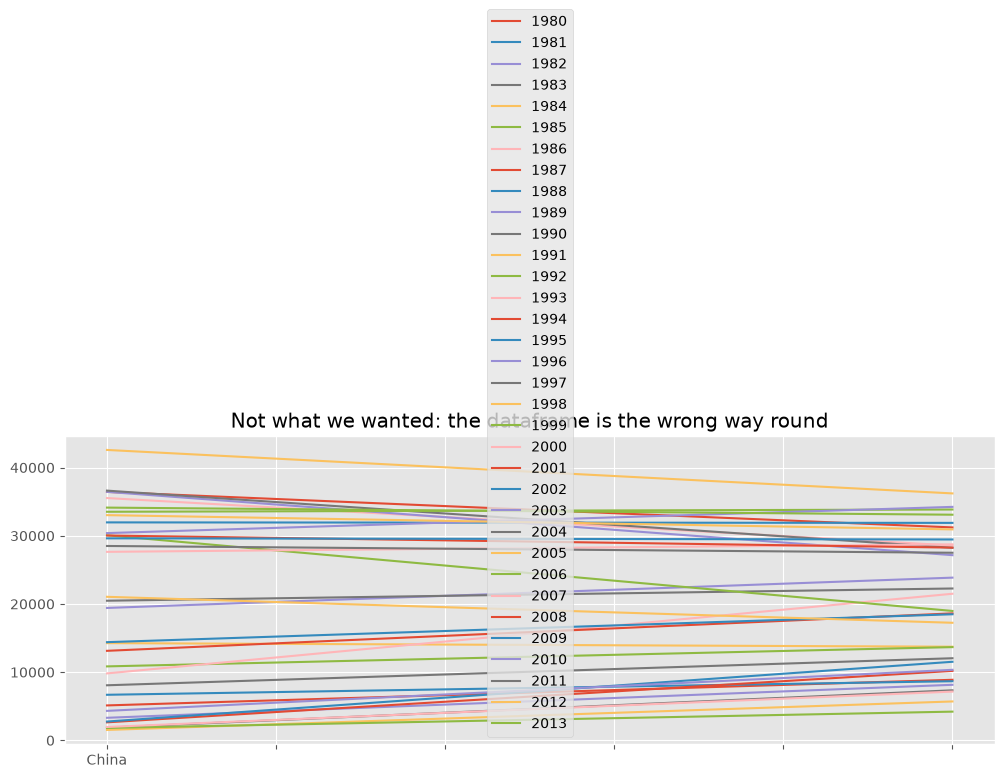

In [22]:
df_CI.plot(kind="line", figsize=(12, 4))

plt.title("Not what we wanted: the dataframe is the wrong way round")
plt.show()

**Step 3 — transpose.** One `transpose()` swaps rows and columns, so the years become the
index (x-axis) and the two countries become the two lines. This is *the* lesson of the lab:
`df.plot()` always plots the index on x, so the data must be oriented before it is drawn.

In [23]:
df_CI = df_CI.transpose()
df_CI.head()

,China,India
1980,5123,8880
1981,6682,8670
1982,3308,8147
1983,1863,7338
1984,1527,5704


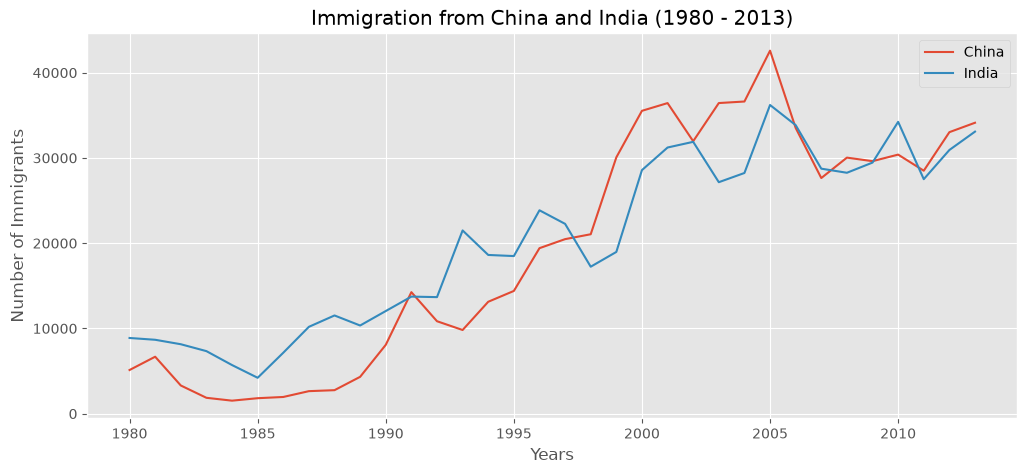

In [24]:
df_CI.index = df_CI.index.map(int)

df_CI.plot(kind="line", figsize=(12, 5))

plt.title("Immigration from China and India (1980 - 2013)")
plt.ylabel("Number of Immigrants")
plt.xlabel("Years")

plt.show()

**Reading the chart.** Both countries grow from a few thousand arrivals a year in the
early 1980s to more than 30,000 a year after 2005, and they cross repeatedly — India ends
2013 at **33,087** and China at **34,129**. Two lines on one canvas make the *comparison*
(the whole point) possible in a way two separate charts would not.

---
## Step 8 — Line plot, question 2: the top 5 source countries

> **Question.** Compare the trend of the top 5 countries that contributed most to
> immigration to Canada.

**Step 1 — rank with the `Total` column we computed in Step 3**, take the first five rows,
keep only the year columns and transpose.

In [25]:
df_can.sort_values(by="Total", ascending=False, axis=0, inplace=True)

df_top5 = df_can.head(5)
df_top5 = df_top5[years].transpose()

print("Top 5 source countries:", df_can.head(5).index.tolist())
print(df_top5.head(3))

Top 5 source countries: ['India', 'China', 'United Kingdom of Great Britain and Northern Ireland', 'Philippines', 'Pakistan']
      India  China  United Kingdom of Great Britain and Northern Ireland  Philippines  Pakistan
1980   8880   5123                                              22045            6051       978
1981   8670   6682                                              24796            5921       972
1982   8147   3308                                              20620            5249      1201


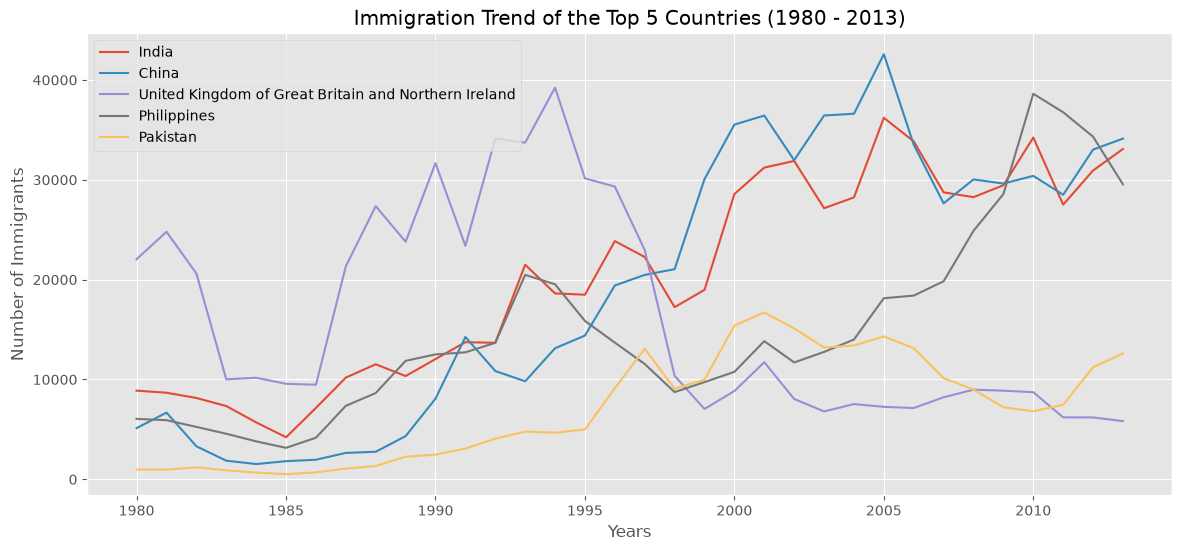

In [26]:
df_top5.index = df_top5.index.map(int)

df_top5.plot(kind="line", figsize=(14, 6))

plt.title("Immigration Trend of the Top 5 Countries (1980 - 2013)")
plt.ylabel("Number of Immigrants")
plt.xlabel("Years")

plt.show()

**Reading the chart.** India and China separate from the pack from about 1995 onwards —
both roughly *ten-fold* between 1995 and 2013 — while the United Kingdom, the Philippines
and Pakistan grow far more gently. Four lines is comfortable; the lab's advice is to stop
around 5–10 lines, after which a line chart stops being readable and a small-multiple grid
or a heat map is the better tool.

---
## What I learned (evidence of learning)

| Requirement of the lab | Where it is shown |
|---|---|
| Read an Excel sheet with `read_excel()` and `skiprows` / `skipfooter` | Step 2 |
| Inspect a DataFrame (`head`, `tail`, `info`, `columns`, `index`, `shape`) | Steps 2.1–2.3 |
| Clean: drop, rename, add `Total`, `isnull`, `describe` | Step 3 |
| Column / row selection with `loc` and `iloc`, `set_index` | Step 4, 4.1 |
| Boolean filtering (`&`, parentheses) | Step 4.2 |
| Line plot with `df.plot()`, titles, axis labels, `plt.text()`, `plt.show()` | Steps 6.1–6.3 |
| Transpose a DataFrame for plotting | Step 7 |
| Rank and compare top-5 countries | Step 8 |

**The one idea to keep.** In pandas, the *index* goes on the x-axis and every *column*
becomes a line. Every "why does my plot look wrong?" moment in this lab was really a
"my dataframe is the wrong way round" moment — reshape first, then draw.